# 12 — Consistent final comparison of the four pricing stages

Use the same **321 frozen months, 2000-01 through 2026-09**, corrected FX mean equations,
**zero equity alphas**, audited instruments and five observed series in every model. Compare both
USD and EUR investors under the retained `scalar11` and `grouped21` covariance models. The latter
has two shock lags and one covariance lag. Run notebook 11 first, then **Run All** in the existing
Miniconda **base** kernel. No downloads or API keys are used.

All four stages include estimated world, currency and local risk prices. Instrument slopes are
added in a fixed sequence; a constant FX price is distinct from no priced FX risk. This notebook
reuses [local_risk_pricing.py](local_risk_pricing.py), without changing earlier engines or outputs.
Earlier VAR-based FX-mean specifications are excluded from this comparison.

In [1]:
SNAPSHOT="data/fixed_2026-11-13/from_2000-01"
UPSTREAM="output/11_pricing_errors/fixed_2026-11-13/2000-01_2026-09/equity_alphas"
COVARIANCE_MODELS=["scalar11","grouped21"]
HAC_LAGS=[0,3,6,12]
TEST_LAGS=12
MAX_ITER=2600
SE_STEP_TOL=.01
REUSE_FITS=True
MODEL_VERSION="aligned_four_stage_ladder_v1"

from pathlib import Path
from io import BytesIO
import hashlib,importlib,importlib.metadata,json,os,platform,sys
ROOT=Path.cwd()
os.environ.setdefault("MPLCONFIGDIR",str(ROOT/".cache"/"matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from packaging.version import Version
if Version(importlib.metadata.version("statsmodels"))<Version("0.15.0"):raise RuntimeError("Update statsmodels to 0.15.0 and restart the same base kernel.")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__!=importlib.metadata.version("statsmodels"):
    raise RuntimeError("Restart the same kernel to discard old statsmodels imports.")
from statsmodels.stats.multitest import multipletests
from IPython.display import display,Markdown
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
import pricing_robustness as base
import covariance_robustness as covariance
import local_risk_pricing as model
importlib.reload(base);importlib.reload(covariance);importlib.reload(model)
versions={p:importlib.metadata.version(p) for p in ["numpy","pandas","scipy","statsmodels","matplotlib"]}
engine_hashes={p:hashlib.sha256((ROOT/p).read_bytes()).hexdigest() for p in ["pricing_robustness.py","covariance_robustness.py","local_risk_pricing.py","pricing_error_tests.py"]}
print("Python:",sys.executable);print("Packages:",versions)
if not COVARIANCE_MODELS or len(set(COVARIANCE_MODELS))!=len(COVARIANCE_MODELS) or any(m not in ["scalar11","grouped21"] for m in COVARIANCE_MODELS):raise ValueError("Use the retained covariance models.")
if not HAC_LAGS or 0 not in HAC_LAGS or len(set(HAC_LAGS))!=len(HAC_LAGS) or any(type(h)!=int or h<0 for h in HAC_LAGS):raise ValueError("Include zero and distinct nonnegative integer HAC lags.")
pd.set_option("display.max_columns",18);pd.set_option("display.max_rows",50);pd.options.display.float_format=lambda x:f"{x:.6g}"
plt.rcParams.update({"figure.dpi":120,"font.size":10,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.16})
source,upstream=ROOT/SNAPSHOT,ROOT/UPSTREAM
manifest=json.loads((source/"manifest.json").read_text());raw=(source/"dataset.csv").read_bytes()
if not manifest.get("sealed") or hashlib.sha256(raw).hexdigest()!=manifest["exports"]["dataset.csv"]:raise ValueError("Frozen dataset checksum differs.")
data=pd.read_csv(BytesIO(raw),index_col=0,float_precision="round_trip");data.index=pd.PeriodIndex(data.index,freq="M",name="month")
if not data.index.equals(pd.period_range(data.index[0],data.index[-1],freq="M")):raise ValueError("Discontinuous model months.")
if max(HAC_LAGS)>=len(data):raise ValueError("HAC bandwidth exceeds the sample.")
upstream_hashes,conditioning_hashes={},{}
def upstream_bytes(name):
    content=(upstream/name).read_bytes();upstream_hashes[name]=hashlib.sha256(content).hexdigest();return content
prior=json.loads(upstream_bytes("estimation_manifest.json"))
if (prior["source_dataset_sha256"]!=manifest["exports"]["dataset.csv"] or prior["first"]!=str(data.index[0]) or prior["last"]!=str(data.index[-1]) or prior["observations"]!=len(data)):
    raise ValueError("Notebook 11 sample differs.")
for name,digest in prior["engines"].items():
    if engine_hashes[name]!=digest:raise ValueError("An upstream likelihood engine changed.")
conditioning_root=ROOT/prior["conditioning_root"]
def conditioning_bytes(name):
    content=(conditioning_root/name).read_bytes();digest=hashlib.sha256(content).hexdigest()
    if digest!=prior["conditioning_file_sha256"][name]:raise ValueError(f"Conditioning checksum differs: {name}")
    conditioning_hashes[name]=digest;return content
old_summary=pd.read_csv(BytesIO(upstream_bytes("fit_summary.csv")),index_col=0,float_precision="round_trip")
if len(prior["local_specifications"])!=2:raise ValueError("Run notebook 11 with its audited time-varying local sensitivity first.")
local_transform=next(s for s in prior["local_specifications"] if s!="constant")
inflation=pd.read_csv(BytesIO(conditioning_bytes("inflation_reconstruction.csv")),index_col=0,float_precision="round_trip")
inflation.index=pd.PeriodIndex(inflation.index,freq="M")
samples,designs,design_columns,references={}, {}, {}, {}
for currency,gap in [("USD","US_HU"),("EUR","EA_HU")]:
    designs[currency],design_columns[currency]={},{}
    for label in ["W","H","O"]:
        z=pd.read_csv(BytesIO(conditioning_bytes(f"conditioning_{currency.lower()}_{label}.csv")),index_col=0,float_precision="round_trip")
        if not pd.PeriodIndex(z.index,freq="M").equals(data.index):raise ValueError("Conditioning months differ.")
        designs[currency][label]=z.to_numpy();design_columns[currency][label]=list(z.columns)
    frame=pd.DataFrame({f"inflation_gap_{local_transform}_lag2_pp":inflation[f"{local_transform}_{gap}_lag2_pp"],"floating_regime_known":data["floating_regime_known"]},index=data.index)
    designs[currency]["L"]=np.c_[np.ones(len(data)),((frame-frame.mean())/frame.std(ddof=1)).to_numpy()]
    design_columns[currency]["L"]=["constant"]+list(frame.columns)
    equity=data[[f"rx_{a}_{currency.lower()}" for a in ["world","us","hu"]]].to_numpy()*100
    fx=np.c_[data[f"fx_huf_{currency.lower()}"]*100,data["fx_eur_usd"]*100*(1 if currency=="USD" else -1)]
    samples[currency]=np.c_[equity,fx]
    for name in COVARIANCE_MODELS:
        for stage,specification in [(3,"constant"),(4,local_transform)]:
            key=f"{currency}_{name}_{specification}_zero"
            with np.load(BytesIO(upstream_bytes(f"parameters_{key}.npz")),allow_pickle=False) as a:references[(currency,name,stage)]={k:a[k].copy() for k in a.files}
            if not np.array_equal(references[(currency,name,stage)]["equity_alphas"],np.zeros(3)):raise ValueError("Reference equity alphas are not zero.")
OUT=ROOT/"output"/"12_final_model_comparison"/source.parent.name/f"{data.index[0]}_{data.index[-1]}"/"corrected_FX_zero_alphas"
OUT.mkdir(parents=True,exist_ok=True)
STAGES={1:"Constant prices",2:"TV world",3:"TV world + FX",4:"TV world + FX + HU local"}
display(pd.DataFrame({"first":[str(data.index[0])],"last":[str(data.index[-1])],"months":[len(data)],"equity_alphas":["fixed zero"],"FX_means":["pricing equations in all stages"]}))

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8'}


,first,last,months,equity_alphas,FX_means
0,2000-01,2026-09,321,fixed zero,pricing equations in all stages


## 1. Define one nested ladder

For every row, use the same five-series conditional mean system:

$$\boxed{\mu_{i,t}=\lambda_{W,t}H_{iW,t}+\lambda_{H,t}H_{iH,t}+\lambda_{O,t}H_{iO,t}
+\mathbf{1}_{i=US}\lambda_{US}H_{US,US,t}+\mathbf{1}_{i=HU}\lambda_{HU,t}H_{HU,HU,t}.}$$

All equity pricing-error alphas are fixed at zero. Both FX rows are priced by the same world/FX
covariances, with no additional intercept or VAR equation. This maintains the supplied draft's
[currency-mean restriction](https://www.efmaefm.org/0EFMAMEETINGS/EFMA%20ANNUAL%20MEETINGS/2005-Milan/papers/14-antell_paper.pdf),
while retaining our documented public-data, two-FX, instrument and covariance adaptations.

| Stage | World price | Two FX prices | Hungarian local price | Added slopes | Scalar / grouped parameters |
|---|---|---|---|---:|---:|
| 1 | Constant | Constant | Constant | — | 22 / 29 |
| 2 | Audited global instruments | Constant | Constant | 3 | 25 / 32 |
| 3 | Same as 2 | Audited FX instruments | Constant | 9 | 34 / 41 |
| 4 | Same as 2 | Same as 3 | Audited inflation/regime instruments | 2 | 36 / 43 |

The US local price stays constant. Each stage includes all five intercept risk prices; none drops
currency risk. Instrument columns, scaling and timing are inherited exactly, rather than reselected
from p-values. Stage 4 uses notebook 10's primary local transform (default: lagged gap **change**).
All models retain their free $CC'$ covariance intercept; variance targeting remains a documented
methodological difference from the paper.

Rank AIC/BIC **within each investor perspective**. Both covariance choices enter those descriptive
rankings, but they need not tell the same story as residual diagnostics. Do not rank investor
currencies against one another. The USD/EUR cash proxies and instrument definitions are retained;
these are not a pure change-of-numeraire invariance experiment.

In [2]:
def make_case(currency,name,stage):
    active={"W":stage>=2,"H":stage>=3,"O":stage>=3,"L":stage>=4}
    pdsg={a:designs[currency][a].copy() if active[a] else np.ones((len(data),1)) for a in ["W","H","O","L"]}
    columns={a:list(design_columns[currency][a]) if active[a] else ["constant"] for a in pdsg}
    if any(not np.isfinite(z).all() or np.linalg.matrix_rank(z)!=z.shape[1] for z in pdsg.values()):raise ValueError("Invalid pricing design.")
    y=samples[currency]
    return {"id":f"{currency}_{name}_S{stage}","currency":currency,"name":name,"stage":stage,"y":y,"pdesign":pdsg,"columns":columns,"scales":y.std(axis=0,ddof=1)}
def args(case):return (case["y"],case["pdesign"],case["scales"],case["name"])
def map_theta(theta,old,new):
    if old["name"]!=new["name"]:raise ValueError("Map within one covariance model.")
    ko=model.layout(old["pdesign"],old["name"])[0];kn=model.layout(new["pdesign"],new["name"])[0]
    result=np.r_[np.zeros(kn),theta[ko:]];result[1]=theta[1]
    oi,ni=model.price_indices(old["pdesign"]),model.price_indices(new["pdesign"])
    for label,positions in ni.items():
        for j,column in zip(positions,new["columns"][label]):
            if column in old["columns"][label]:result[j]=theta[oi[label][old["columns"][label].index(column)]]
    return result

def added_indices(case):
    idx=model.price_indices(case["pdesign"])
    return {2:idx["W"][1:],3:np.r_[idx["H"][1:],idx["O"][1:]],4:idx["L"][1:]}.get(case["stage"],np.array([],dtype=int))
checks,reference_rows=[],[]
for currency in ["USD","EUR"]:
    for name in COVARIANCE_MODELS:
        for stage in [3,4]:
            case=make_case(currency,name,stage);saved=references[(currency,name,stage)];f=model.filter_model(saved["theta"],*args(case))
            for new,old in [("H","H"),("mu","mu"),("errors","residuals"),("scores","scores")]:np.testing.assert_allclose(f[new],saved[old],atol=1e-8,rtol=1e-9)
            spec="constant" if stage==3 else local_transform
            np.testing.assert_allclose(-f["losses"].sum(),old_summary.loc[f"{currency}_{name}_{spec}_zero","loglik"],atol=1e-8,rtol=0)
            reference_rows.append({"case":case["id"],"reference_loglik":-f["losses"].sum(),"reference_gradient":np.max(np.abs(f["scores"].mean(axis=0)))})
        for stage in STAGES:
            case=make_case(currency,name,stage);probe=model.initial_theta(*args(case))
            for positions in model.price_indices(case["pdesign"]).values():probe[positions[1:]]=np.linspace(.12,-.08,len(positions)-1)
            sub=(case["y"][:35],{a:z[:35] for a,z in case["pdesign"].items()},case["scales"],name)
            analytic=model.objective(probe,*sub)[1];numeric=base.numerical_gradient(lambda t:model.objective(t,*sub)[0],probe)
            np.testing.assert_allclose(analytic,numeric,atol=5e-6,rtol=5e-5)
            if stage<4:
                child=make_case(currency,name,stage+1);expanded=map_theta(probe,case,child)
                np.testing.assert_allclose(expanded[added_indices(child)],0,atol=0,rtol=0)
                for key in ["H","mu","losses"]:np.testing.assert_allclose(model.filter_model(expanded,*args(child))[key],model.filter_model(probe,*args(case))[key],atol=1e-9,rtol=1e-11)
            checks.append({"perspective":currency,"covariance":name,"stage":stage,"parameters":len(probe),"gradient_error":np.max(np.abs(analytic-numeric))})
reference_audit=pd.DataFrame(reference_rows).set_index("case")
display(reference_audit);display(pd.DataFrame(checks))

,reference_loglik,reference_gradient
case,,
USD_scalar11_S3,-3719.31,1.23547e-06
USD_scalar11_S4,-3719.14,3.67277e-06
USD_grouped21_S3,-3711.35,2.29723e-06
USD_grouped21_S4,-3711.3,7.98959e-07
EUR_scalar11_S3,-3716.44,1.45493e-06
EUR_scalar11_S4,-3716.32,1.00728e-06
EUR_grouped21_S3,-3708.52,3.46223e-06
EUR_grouped21_S4,-3708.38,2.70138e-06


,perspective,covariance,stage,parameters,gradient_error
0,USD,scalar11,1,22,1.36602e-08
1,USD,scalar11,2,25,1.36077e-08
2,USD,scalar11,3,34,1.36274e-08
3,USD,scalar11,4,36,1.36222e-08
4,USD,grouped21,1,29,1.15652e-08
5,USD,grouped21,2,32,1.17594e-08
6,USD,grouped21,3,41,1.17308e-08
7,USD,grouped21,4,43,1.16223e-08
8,EUR,scalar11,1,22,2.3463e-08
9,EUR,scalar11,2,25,2.34909e-08


## 2. Fit or recheck every stage from matched starts

Re-estimate stages 1 and 2 under the corrected FX means. Recheck stages 3 and 4 from both their
verified prior estimates and the newly fitted nested parent. This can reveal a better solution than
the earlier starting points. Stage 1 also uses an independent moment start; stage 2 uses the parent,
a projection of stage 3's reference, and a moment start. Each fit must have optimizer success, a small
raw gradient, no better unconverged candidate and likelihood at least as good as its nested parent.
Keep prior outputs unchanged and save all new estimates here.

Caches include all input arrays, engine hashes, optimizer settings, package versions and exact start
hashes. Re-filter each cached estimate; `REUSE_FITS=False` repeats all optimization. Numerical
convergence and inference readiness are separate checks.

In [3]:
fits,start_rows={},[]
for currency in ["USD","EUR"]:
    for name in COVARIANCE_MODELS:
        for stage in STAGES:
            case=make_case(currency,name,stage);key=case["id"];print(key,flush=True)
            parent=fits.get(f"{currency}_{name}_S{stage-1}")
            if stage==1:
                reference=make_case(currency,name,3)
                starts=[map_theta(references[(currency,name,3)]["theta"],reference,case),model.initial_theta(*args(case))]
                start_labels=["projected stage 3 reference","independent moment"]
            elif stage==2:
                reference=make_case(currency,name,3)
                starts=[map_theta(parent["theta"],parent,case),map_theta(references[(currency,name,3)]["theta"],reference,case),model.initial_theta(*args(case))]
                start_labels=["nested parent","projected stage 3 reference","independent moment"]
            else:
                starts=[references[(currency,name,stage)]["theta"],map_theta(parent["theta"],parent,case)]
                start_labels=["verified prior estimate","nested parent"]
            config={"version":MODEL_VERSION,"engines":engine_hashes,"source_sha256":manifest["exports"]["dataset.csv"],"case":key,
                "first":str(data.index[0]),"last":str(data.index[-1]),"n":len(data),"python":platform.python_version(),"packages":versions,
                "max_iter":MAX_ITER,"start_labels":start_labels,"start_sha256":[hashlib.sha256(t.tobytes()).hexdigest() for t in starts],
                "upstream_sha256":upstream_hashes,"conditioning_sha256":conditioning_hashes,"price_columns":case["columns"]}
            payload=json.dumps(config,sort_keys=True).encode()+case["y"].tobytes()+b"".join(case["pdesign"][a].tobytes() for a in ["W","H","O","L"])
            fingerprint=hashlib.sha256(payload).hexdigest();path=OUT/f"fit_{key}.json"
            cached=json.loads(path.read_text()) if REUSE_FITS and path.exists() else None
            limits=model.bounds(case["pdesign"],name);candidate=np.asarray(cached["theta"]) if cached else np.array([])
            record=None
            if candidate.shape==(len(limits),) and cached.get("fingerprint")==fingerprint and np.isfinite(candidate).all() and (candidate>=limits[:,0]).all() and (candidate<=limits[:,1]).all():
                value,gradient=model.objective(candidate,*args(case))
                if abs(value-cached["mean_nll"])<1e-8 and np.max(np.abs(gradient))<1e-4:record=cached;print("  verified cached fit",flush=True)
            if record is None:
                best,runs=model.fit_starts(args(case),starts,maxiter=MAX_ITER)
                record={"fingerprint":fingerprint,"configuration":config,"theta":best.x.tolist(),"mean_nll":float(best.fun),"starts":runs}
                path.write_text(json.dumps(record,indent=2)+"\n")
            for row in record["starts"]:start_rows.append({"case":key,**row,"start_label":start_labels[row["start"]-1]})
            theta=np.asarray(record["theta"]);case.update(theta=theta,filter=model.filter_model(theta,*args(case)))
            if parent and case["filter"]["losses"].sum()>parent["filter"]["losses"].sum()+1e-5:raise ValueError("Expanded stage fits worse than its nested parent.")
            if stage>=3 and -case["filter"]["losses"].sum()<reference_audit.loc[key,"reference_loglik"]-1e-5:raise ValueError("Rechecked fit is worse than its verified reference.")
            fits[key]=case
starting_points=pd.DataFrame(start_rows);display(starting_points)

USD_scalar11_S1


  verified cached fit


USD_scalar11_S2


  verified cached fit


USD_scalar11_S3


  verified cached fit


... (23 outputs left out)

  verified cached fit


EUR_grouped21_S4


  verified cached fit


,case,start,success,mean_nll,max_abs_gradient,iterations,message,start_label
0,USD_scalar11_S1,1,True,11.6349,1.32545e-07,77,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,projected stage 3 reference
1,USD_scalar11_S1,2,True,11.6349,8.2387e-08,81,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL,independent moment
2,USD_scalar11_S2,1,True,11.6318,7.25945e-07,101,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,nested parent
3,USD_scalar11_S2,2,True,11.6318,1.10025e-06,110,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,projected stage 3 reference
4,USD_scalar11_S2,3,True,11.6318,9.01402e-08,112,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL,independent moment
5,USD_scalar11_S3,1,True,11.5866,1.01815e-06,3,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,verified prior estimate
6,USD_scalar11_S3,2,True,11.5866,1.31695e-06,226,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,nested parent
7,USD_scalar11_S4,1,True,11.5861,4.74976e-06,56,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,verified prior estimate
8,USD_scalar11_S4,2,True,11.5861,6.86415e-06,127,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,nested parent
9,USD_grouped21_S1,1,True,11.6133,1.13915e-06,132,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,projected stage 3 reference


## 3. Compare fit, incremental restrictions and adequacy

Each adjacent restriction sets only the newly added slopes to zero: **3 df** for world variation,
**9 df** for joint FX variation, **2 df** for Hungarian local variation. Test them at the expanded
stage with the full joint sandwich covariance, using the same Bartlett HAC bandwidths **0, 3, 6, 12**.
These are conditional tests within the specified ladder, not ordinary LR tests. No chi-square
likelihood-ratio p-value is supplied under the Gaussian quasi-likelihood.

Report AIC/BIC both relative to the best model within a perspective and relative to stage 1 within
the same covariance model. AIC/BIC are descriptive criteria; they do not establish correct pricing
or calibrate an exhaustive model search. The data were already explored. Price constancy is also
distinct from zero pricing; retain the separate zero-risk-price tests.

Apply the established curvature, parameter-bound and two-step SE-stability gates before reporting
ordinary inference. Maintain nominal and within-family Holm-adjusted residual screens. These are
approximate after estimating GARCH parameters. HAC changes uncertainty and does not repair
misspecification. Keep covariance diagnostics visible alongside each criterion winner.

In [4]:
summary_rows,test_rows,price_rows,residual_rows,cross_rows,premium_rows=[],[],[],[],[],[]
for key,case in fits.items():
    theta,f=case["theta"],case["filter"];inf=model.inference(theta,args(case),f,hac_lags=HAC_LAGS,se_step_tol=SE_STEP_TOL);case["inference"]=inf
    labels=["World","US equity","Hungary equity","HUF FX",("EUR FX" if case["currency"]=="USD" else "USD FX")]
    marginal,cross=base.diagnostics(f,labels,TEST_LAGS)
    for column in ["LB_z_p","LB_z_squared_p","ARCH_LM_p"]:marginal[column.replace("_p","_holm_p")]=multipletests(marginal[column],method="holm")[1]
    cross["LB_product_holm_p"]=multipletests(cross["LB_product_p"],method="holm")[1]
    residual_rows.extend({"case":key,"series":label,**row.to_dict()} for label,row in marginal.iterrows())
    cross_rows.extend({"case":key,"pair":label,**row.to_dict()} for label,row in cross.iterrows())
    LL=-f["losses"].sum();q=len(theta);idx=model.price_indices(case["pdesign"])
    summary_rows.append({"case":key,"perspective":case["currency"],"covariance":case["name"],"stage":case["stage"],"model":STAGES[case["stage"]],"n":len(data),"parameters":q,
        "loglik":LL,"AIC":-2*LL+2*q,"BIC":-2*LL+np.log(len(data))*q,"gradient":np.max(np.abs(f["scores"].mean(axis=0))),
        "Hessian_condition":inf["Hessian_condition"],"near_bound":inf["near_bound"],"minimum_bound_distance":inf["distance_to_bounds"].min(),
        "ready_all_lags":all(v["ready"] for v in inf["estimates"].values()),"mean_flags":int((marginal["LB_z_p"]<.05).sum()),
        "variance_flags":int(((marginal["LB_z_squared_p"]<.05)|(marginal["ARCH_LM_p"]<.05)).sum()),"cross_flags":int((cross["LB_product_p"]<.05).sum()),
        "variance_flags_holm":int(((marginal["LB_z_squared_holm_p"]<.05)|(marginal["ARCH_LM_holm_p"]<.05)).sum()),"cross_flags_holm":int((cross["LB_product_holm_p"]<.05).sum())})
    restrictions={"World price zero":idx["W"],"FX prices zero":np.r_[idx["H"],idx["O"]],"Hungarian local price zero":idx["L"],"Local prices jointly zero":np.r_[1,idx["L"]]}
    if len(idx["W"])>1:restrictions["World price constant"]=idx["W"][1:]
    if len(idx["H"])>1:restrictions["FX prices constant"]=np.r_[idx["H"][1:],idx["O"][1:]]
    if len(idx["L"])>1:restrictions["Hungarian local price constant"]=idx["L"][1:]
    if case["stage"]>1:restrictions["Added slopes zero"]=added_indices(case)
    for lag,estimate in inf["estimates"].items():
        V=estimate["covariance"]
        for label,positions in restrictions.items():test_rows.append({"case":key,"HAC_lags":lag,"test":label,**base.wald(theta,V,positions),"inference_ready":estimate["ready"],"reason":estimate["reason"],"SE_step_difference":estimate["price_SE_step_difference"]})
        for label,positions in idx.items():
            for j,instrument in zip(positions,case["columns"][label]):price_rows.append({"case":key,"HAC_lags":lag,"price":label,"instrument":instrument,"estimate":base.PRICE_SCALE*theta[j],"robust_se":base.PRICE_SCALE*np.sqrt(V[j,j])})
        price_rows.append({"case":key,"HAC_lags":lag,"price":"US_local","instrument":"constant","estimate":base.PRICE_SCALE*theta[1],"robust_se":base.PRICE_SCALE*np.sqrt(V[1,1])})
    p=pd.DataFrame({"world":f["world_prices"]*f["H"][:,2,0],"HUF_FX":f["fx_prices"][:,0]*f["H"][:,2,3],"other_FX":f["fx_prices"][:,1]*f["H"][:,2,4],"local":f["local_prices"]*f["H"][:,2,2]},index=data.index)
    np.testing.assert_allclose(p.sum(axis=1),f["mu"][:,2],atol=1e-11,rtol=1e-11);case["premia"]=p.assign(total=f["mu"][:,2])
    for component in case["premia"]:premium_rows.append({"case":key,"component":component,"mean_monthly_pp":case["premia"][component].mean(),"sd_monthly_pp":case["premia"][component].std(ddof=1)})
summary=pd.DataFrame(summary_rows).set_index("case")
for column in ["AIC","BIC"]:
    summary[f"{column}_from_best"]=summary[column]-summary.groupby("perspective")[column].transform("min")
    summary[f"{column}_minus_S1"]=[row[column]-summary.loc[f"{row.perspective}_{row.covariance}_S1",column] for _,row in summary.iterrows()]
for key,row in reference_audit.iterrows():reference_audit.loc[key,"rechecked_loglik_gain"]=summary.loc[key,"loglik"]-row["reference_loglik"]
tests=pd.DataFrame(test_rows).set_index(["case","HAC_lags","test"]);price_coefficients=pd.DataFrame(price_rows).set_index(["case","HAC_lags","price","instrument"])
residuals=pd.DataFrame(residual_rows).set_index(["case","series"]);cross_diagnostics=pd.DataFrame(cross_rows).set_index(["case","pair"])
premium_summary=pd.DataFrame(premium_rows).set_index(["case","component"])
display(summary);display(tests.xs("Added slopes zero",level="test")[["robust_p_value","inference_ready","reason"]].unstack("HAC_lags"))

,perspective,covariance,stage,model,n,parameters,loglik,AIC,BIC,...,mean_flags,variance_flags,cross_flags,variance_flags_holm,cross_flags_holm,AIC_from_best,AIC_minus_S1,BIC_from_best,BIC_minus_S1
case,,,,,,,,,,,,,,,,,,,
USD_scalar11_S1,USD,scalar11,1,Constant prices,321,22,-3734.81,7513.62,7596.59,...,0,4,3,4,0,8.91664,0,0,0
USD_scalar11_S2,USD,scalar11,2,TV world,321,25,-3733.8,7517.61,7611.9,...,0,4,1,3,0,12.9035,3.98683,15.3012,15.3012
USD_scalar11_S3,USD,scalar11,3,TV world + FX,321,34,-3719.31,7506.63,7634.85,...,0,4,0,1,0,1.91919,-6.99744,38.2598,38.2598
USD_scalar11_S4,USD,scalar11,4,TV world + FX + HU local,321,36,-3719.14,7510.28,7646.06,...,0,4,0,1,0,5.57853,-3.33811,49.4621,49.4621
USD_grouped21_S1,USD,grouped21,1,Constant prices,321,29,-3727.86,7513.71,7623.09,...,0,2,2,0,0,9.00731,0,26.4908,0
USD_grouped21_S2,USD,grouped21,2,TV world,321,32,-3726.68,7517.36,7638.04,...,0,2,1,0,0,12.6523,3.64497,41.45,14.9593
USD_grouped21_S3,USD,grouped21,3,TV world + FX,321,41,-3711.35,7504.71,7659.34,...,0,1,0,0,0,0,-9.00731,62.7407,36.25
USD_grouped21_S4,USD,grouped21,4,TV world + FX + HU local,321,43,-3711.3,7508.6,7670.77,...,0,1,0,0,0,3.89296,-5.11435,74.1766,47.6858
EUR_scalar11_S1,EUR,scalar11,1,Constant prices,321,22,-3735.31,7514.62,7597.59,...,1,3,0,0,0,15.5877,0,0,0


robust_p_value                                      \
HAC_lags                     0           3           6           12   
case                                                                  
USD_scalar11_S2        0.624823    0.552875    0.546256    0.474489   
USD_scalar11_S3     0.000564708 7.81914e-05  5.0434e-06 1.64633e-07   
USD_scalar11_S4        0.828853    0.825823     0.83002    0.845565   
USD_grouped21_S2       0.561522     0.50386    0.475825    0.399464   
USD_grouped21_S3     0.00020281 2.18956e-05 2.18025e-06 4.13782e-08   
USD_grouped21_S4       0.949303    0.944377    0.943071    0.948189   
EUR_scalar11_S2        0.910155    0.890291    0.841271    0.823172   
EUR_scalar11_S3     8.50145e-06 4.76436e-06 3.87035e-07 4.62669e-10   
EUR_scalar11_S4        0.853223    0.867888    0.873384    0.887612   
EUR_grouped21_S2       0.886043    0.880105     0.83198    0.805307   
EUR_grouped21_S3    3.29699e-05 1.96012e-05  1.0588e-05 6.09767e-08   
EUR_grouped21_S4       0.835465    0.854209    0.861273    0.876115   

                 inference_ready                               reason  \
HAC_lags                      0     3     6     12                 0    
case                                                                    
USD_scalar11_S2             True  True  True  True  numerically ready   
USD_scalar11_S3             True  True  True  True  numerically ready   
USD_scalar11_S4             True  True  True  True  numerically ready   
USD_grouped21_S2            True  True  True  True  numerically ready   
USD_grouped21_S3            True  True  True  True  numerically ready   
USD_grouped21_S4            True  True  True  True  numerically ready   
EUR_scalar11_S2             True  True  True  True  numerically ready   
EUR_scalar11_S3             True  True  True  True  numerically ready   
EUR_scalar11_S4             True  True  True  True  numerically ready   
EUR_grouped21_S2            True  True  True  True  numerically ready   
EUR_grouped21_S3            True  True  True  True  numerically ready   
EUR_grouped21_S4            True  True  True  True  numerically ready   

                                                                           
HAC_lags                         3                  6                  12  
case                                                                       
USD_scalar11_S2   numerically ready  numerically ready  numerically ready  
USD_scalar11_S3   numerically ready  numerically ready  numerically ready  
USD_scalar11_S4   numerically ready  numerically ready  numerically ready  
USD_grouped21_S2  numerically ready  numerically ready  numerically ready  
USD_grouped21_S3  numerically ready  numerically ready  numerically ready  
USD_grouped21_S4  numerically ready  numerically ready  numerically ready  
EUR_scalar11_S2   numerically ready  numerically ready  numerically ready  
EUR_scalar11_S3   numerically ready  numerically ready  numerically ready  
EUR_scalar11_S4   numerically ready  numerically ready  numerically ready  
EUR_grouped21_S2  numerically ready  numerically ready  numerically ready  
EUR_grouped21_S3  numerically ready  numerically ready  numerically ready  
EUR_grouped21_S4  numerically ready  numerically ready  numerically ready

## 4. Inspect the aligned rankings and incremental tests

The first figure shows criterion differences across stages and covariance models, separately for
USD and EUR. The second shows the incremental robust Wald tests: dots are HAC(0), bars span the
four fixed bandwidth results. Those bars are a **bandwidth-sensitivity range, not a confidence interval**.
Withheld tests remain in the tables. These are in-sample model comparisons.

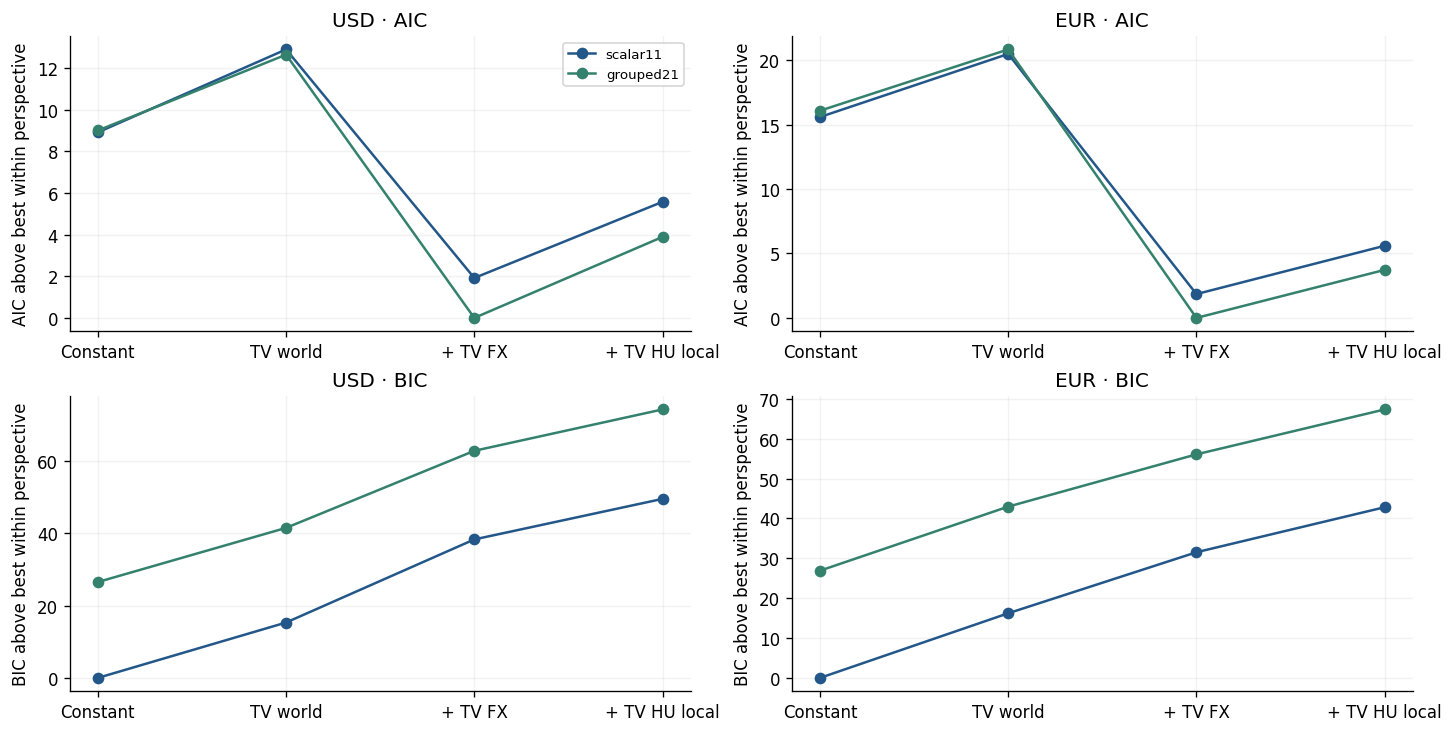

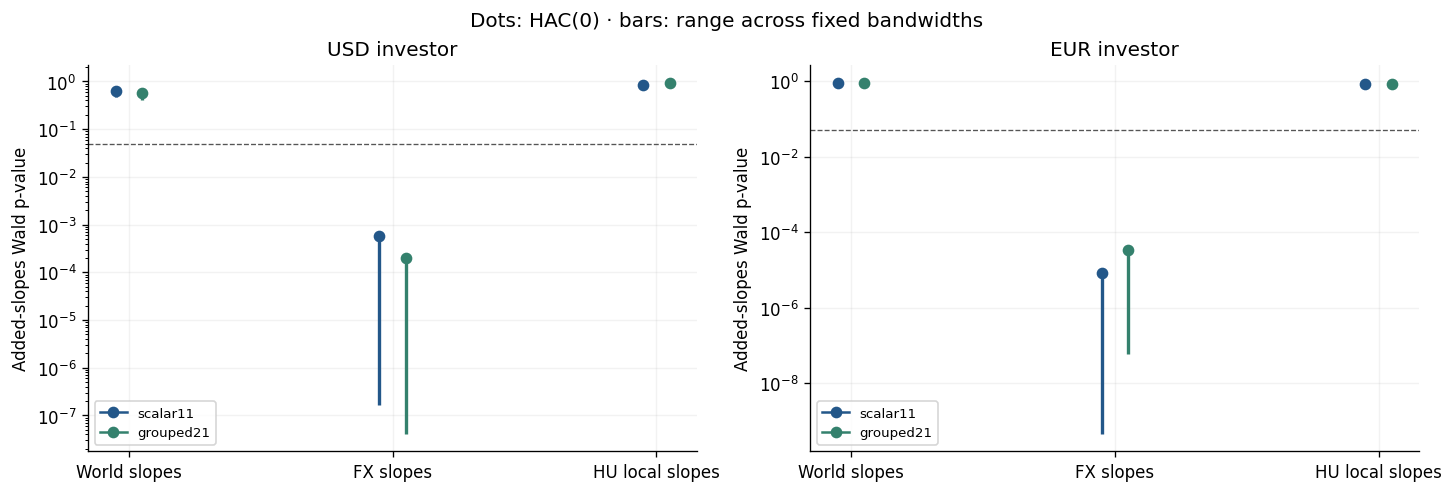

In [5]:
colors={"scalar11":"#235789","grouped21":"#34816d"}
fig,axes=plt.subplots(2,2,figsize=(12,6),layout="constrained",squeeze=False)
for col,currency in enumerate(["USD","EUR"]):
    for row,criterion in enumerate(["AIC","BIC"]):
        ax=axes[row,col]
        for name in COVARIANCE_MODELS:
            q=summary[(summary["perspective"]==currency)&(summary["covariance"]==name)].sort_values("stage")
            ax.plot(q["stage"],q[f"{criterion}_from_best"],marker="o",color=colors[name],label=name)
        ax.set(title=f"{currency} · {criterion}",ylabel=f"{criterion} above best within perspective",xticks=list(STAGES),xticklabels=["Constant","TV world","+ TV FX","+ TV HU local"])
axes[0,0].legend(fontsize=8)
plt.savefig(OUT/"01_aligned_information_criteria.png",dpi=160,bbox_inches="tight");plt.show();plt.close()
fig,axes=plt.subplots(1,2,figsize=(12,4),layout="constrained",squeeze=False)
for ax,currency in zip(axes[0],["USD","EUR"]):
    for m,name in enumerate(COVARIANCE_MODELS):
        for stage in [2,3,4]:
            key=f"{currency}_{name}_S{stage}";p=tests.xs((key,"Added slopes zero"),level=("case","test"))["robust_p_value"].reindex(HAC_LAGS)
            if p.notna().all():
                x=stage+(.10*(m-(len(COVARIANCE_MODELS)-1)/2));ax.vlines(x,p.min(),p.max(),color=colors[name],lw=2)
                ax.plot(x,p.loc[0],marker="o",color=colors[name],label=name if stage==2 else None)
    ax.axhline(.05,color="#555555",lw=.8,ls="--");ax.set_yscale("log")
    ax.set(title=f"{currency} investor",ylabel="Added-slopes Wald p-value",xticks=[2,3,4],xticklabels=["World slopes","FX slopes","HU local slopes"])
    ax.legend(fontsize=8)
fig.suptitle("Dots: HAC(0) · bars: range across fixed bandwidths")
plt.savefig(OUT/"02_incremental_Wald_tests.png",dpi=160,bbox_inches="tight");plt.show();plt.close()

## 5. Save the final comparison and state its limits

Export the complete ladder, starting points, audited references, full joint uncertainty, all restrictions,
price coefficients/paths, designs, residual diagnostics and Hungarian premium decompositions.
Premia are conditional fitted means, not realized returns or out-of-sample forecasts. Their components
sum exactly to the Hungarian conditional excess-return mean; zero alpha adds no separate component.

Report both information criteria and all bandwidths. Keep both covariance models visible even if
one criterion picks a single winner. The remaining targeted robustness work and variance-targeting
sensitivity/documentation still matter before the final research write-up and public release.

In [6]:
final_rows=[]
for key,row in summary.iterrows():
    q={"case":key,"n":row["n"],"parameters":row["parameters"],"AIC_from_best":row["AIC_from_best"],"BIC_from_best":row["BIC_from_best"],
       "AIC_minus_S1":row["AIC_minus_S1"],"BIC_minus_S1":row["BIC_minus_S1"],"ready":row["ready_all_lags"],"variance_flags":row["variance_flags"],"cross_flags":row["cross_flags"]}
    p=tests.xs((key,"Added slopes zero"),level=("case","test"))["robust_p_value"].reindex(HAC_LAGS) if row["stage"]>1 else pd.Series(np.nan,index=HAC_LAGS)
    parent=f"{row.perspective}_{row.covariance}_S{int(row.stage)-1}"
    q["AIC_minus_parent"]=row["AIC"]-summary.loc[parent,"AIC"] if row.stage>1 else np.nan
    q["BIC_minus_parent"]=row["BIC"]-summary.loc[parent,"BIC"] if row.stage>1 else np.nan
    q.update(added_slopes_df=0 if row["stage"]==1 else len(added_indices(fits[key])),added_slopes_p_HAC0=p.loc[0],added_slopes_p_min=p.min(),added_slopes_p_max=p.max())
    final_rows.append(q)
final_summary=pd.DataFrame(final_rows).set_index("case")
tables={"fit_summary.csv":summary,"final_summary.csv":final_summary,"restriction_tests.csv":tests,"price_coefficients.csv":price_coefficients,
    "reference_audit.csv":reference_audit,"starting_points.csv":starting_points,"residual_diagnostics.csv":residuals,
    "cross_covariance_diagnostics.csv":cross_diagnostics,"premium_summary.csv":premium_summary}
for name,table in tables.items():table.to_csv(OUT/name)
for key,case in fits.items():
    f,inf=case["filter"],case["inference"]
    np.savez_compressed(OUT/f"parameters_{key}.npz",theta=case["theta"],H=f["H"],mu=f["mu"],equity_alphas=np.zeros(3),residuals=f["errors"],scores=f["scores"],Hessian=inf["Hessian"],**{f"covariance_HAC{h}":v["covariance"] for h,v in inf["estimates"].items()})
    case["premia"].to_csv(OUT/f"Hungary_decomposition_{key}.csv")
    pd.DataFrame({"world":f["world_prices"],"HUF_FX":f["fx_prices"][:,0],"other_FX":f["fx_prices"][:,1],"HU_local":f["local_prices"],"US_local":f["prices"][1]},index=data.index).to_csv(OUT/f"price_paths_{key}.csv")
    for label,z in case["pdesign"].items():pd.DataFrame(z,index=data.index,columns=case["columns"][label]).to_csv(OUT/f"design_{key}_{label}.csv")
record={"model_version":MODEL_VERSION,"snapshot":SNAPSHOT,"source_dataset_sha256":manifest["exports"]["dataset.csv"],"first":str(data.index[0]),"last":str(data.index[-1]),"observations":len(data),
    "stages":STAGES,"covariance_models":COVARIANCE_MODELS,"equity_alphas":"fixed zero","FX_means":"corrected pricing equations in all stages","local_transform":local_transform,
    "HAC_lags":HAC_LAGS,"test_lags":TEST_LAGS,"SE_step_tolerance":SE_STEP_TOL,"engines":engine_hashes,"upstream":UPSTREAM,"upstream_file_sha256":upstream_hashes,
    "conditioning_root":str(conditioning_root.relative_to(ROOT)),"conditioning_file_sha256":conditioning_hashes,"world_FX_instruments":prior["world_FX_instruments"],"python":platform.python_version(),"packages":versions}
(OUT/"estimation_manifest.json").write_text(json.dumps(record,indent=2,sort_keys=True)+"\n")
display(Markdown("**Aligned final comparison — constant-price stage has no added-slopes test**"));display(final_summary)
for currency in ["USD","EUR"]:
    q=summary[summary["perspective"].eq(currency)];aic=q["AIC"].idxmin();bic=q["BIC"].idxmin()
    display(Markdown(f"**{currency}:** lowest descriptive AIC: `{aic}`; lowest BIC: `{bic}`. "
        f"AIC winner's nominal variance/cross flags: **{int(q.loc[aic,'variance_flags'])}/{int(q.loc[aic,'cross_flags'])}**; "
        f"BIC winner's: **{int(q.loc[bic,'variance_flags'])}/{int(q.loc[bic,'cross_flags'])}**. "
        "A criterion winner is not a specification-validity result."))
for stage,label in [(2,"World-price variation added to constant FX/local prices"),(3,"FX-price variation added to time-varying world pricing"),(4,"Hungarian local-price variation added to the world/FX model")]:
    keys=list(summary[summary["stage"].eq(stage)].index)
    p=tests.loc[[(key,h,"Added slopes zero") for key in keys for h in HAC_LAGS],"robust_p_value"]
    if p.notna().all():
        decision="rejected in every case" if (p<.05).all() else "not rejected in any case" if (p>.05).all() else "mixed across cases/bandwidths"
        display(Markdown(f"**{label}:** the zero-added-slopes null is **{decision}** at 5%; p-values span **{p.min():.4g}–{p.max():.4g}** across both perspectives, covariance models and fixed bandwidths."))
world_p=tests.loc[[(key,h,"World price constant") for key in summary[summary["stage"].eq(3)].index for h in HAC_LAGS],"robust_p_value"]
if world_p.notna().all() and (world_p>.05).all():
    display(Markdown("Within stage 3, world-price constancy is also not rejected. A **constant-world / time-varying-FX** restriction is a natural parsimonious follow-up; "
        "it is outside this predefined four-stage ladder and has not been ranked here."))
display(Markdown("All four stages now share the corrected FX means, zero alphas and identical observations. "
    "Interpret incremental tests conditionally within this ladder; do not combine its rankings with the earlier VAR-based mean models. "
    f"Outputs: `{OUT.relative_to(ROOT)}`. Frozen inputs and upstream outputs were read without updating them."))

**Aligned final comparison — constant-price stage has no added-slopes test**

,n,parameters,AIC_from_best,BIC_from_best,AIC_minus_S1,BIC_minus_S1,ready,variance_flags,cross_flags,AIC_minus_parent,BIC_minus_parent,added_slopes_df,added_slopes_p_HAC0,added_slopes_p_min,added_slopes_p_max
case,,,,,,,,,,,,,,,
USD_scalar11_S1,321,22,8.91664,0,0,0,True,4,3,NaN,NaN,0,NaN,NaN,NaN
USD_scalar11_S2,321,25,12.9035,15.3012,3.98683,15.3012,True,4,1,3.98683,15.3012,3,0.624823,0.474489,0.624823
USD_scalar11_S3,321,34,1.91919,38.2598,-6.99744,38.2598,True,4,0,-10.9843,22.9587,9,0.000564708,1.64633e-07,0.000564708
USD_scalar11_S4,321,36,5.57853,49.4621,-3.33811,49.4621,True,4,0,3.65934,11.2022,2,0.828853,0.825823,0.845565
USD_grouped21_S1,321,29,9.00731,26.4908,0,0,True,2,2,NaN,NaN,0,NaN,NaN,NaN
USD_grouped21_S2,321,32,12.6523,41.45,3.64497,14.9593,True,2,1,3.64497,14.9593,3,0.561522,0.399464,0.561522
USD_grouped21_S3,321,41,0,62.7407,-9.00731,36.25,True,1,0,-12.6523,21.2907,9,0.00020281,4.13782e-08,0.00020281
USD_grouped21_S4,321,43,3.89296,74.1766,-5.11435,47.6858,True,1,0,3.89296,11.4358,2,0.949303,0.943071,0.949303
EUR_scalar11_S1,321,22,15.5877,0,0,0,True,3,0,NaN,NaN,0,NaN,NaN,NaN


**USD:** lowest descriptive AIC: `USD_grouped21_S3`; lowest BIC: `USD_scalar11_S1`. AIC winner's nominal variance/cross flags: **1/0**; BIC winner's: **4/3**. A criterion winner is not a specification-validity result.

**EUR:** lowest descriptive AIC: `EUR_grouped21_S3`; lowest BIC: `EUR_scalar11_S1`. AIC winner's nominal variance/cross flags: **0/0**; BIC winner's: **3/0**. A criterion winner is not a specification-validity result.

**World-price variation added to constant FX/local prices:** the zero-added-slopes null is **not rejected in any case** at 5%; p-values span **0.3995–0.9102** across both perspectives, covariance models and fixed bandwidths.

**FX-price variation added to time-varying world pricing:** the zero-added-slopes null is **rejected in every case** at 5%; p-values span **4.627e-10–0.0005647** across both perspectives, covariance models and fixed bandwidths.

**Hungarian local-price variation added to the world/FX model:** the zero-added-slopes null is **not rejected in any case** at 5%; p-values span **0.8258–0.9493** across both perspectives, covariance models and fixed bandwidths.

Within stage 3, world-price constancy is also not rejected. A **constant-world / time-varying-FX** restriction is a natural parsimonious follow-up; it is outside this predefined four-stage ladder and has not been ranked here.

All four stages now share the corrected FX means, zero alphas and identical observations. Interpret incremental tests conditionally within this ladder; do not combine its rankings with the earlier VAR-based mean models. Outputs: `output/12_final_model_comparison/fixed_2026-11-13/2000-01_2026-09/corrected_FX_zero_alphas`. Frozen inputs and upstream outputs were read without updating them.